# Selected PyramidNet results

This notebook recomputes the model parameter count and validation accuracy from the retained confusion matrix. The matrix comes from the exact checkpoint submitted as 58019390. Kaggle accuracy is read from the saved submission receipt because competition labels are hidden. This notebook does not retrain the model or rerun image inference; `train.py` and `predict.py` provide those entry points, with commands in README.md.

The original checkpoint SHA256 is recorded in `Figures/pyramid_result.json`. The complete training history and validation figure inputs are included in `Figures/`.


In [1]:
import json
import sys
from pathlib import Path
import numpy as np

ROOT = Path.cwd()
if (ROOT / "proj1").is_dir():
    ROOT = ROOT / "proj1"
sys.path.insert(0, str(ROOT))
from model import build_model

result = json.loads((ROOT / "Figures/pyramid_result.json").read_text())
model = build_model(result["model"])
parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert parameters == result["parameters"] == 4_804_512
assert parameters <= 5_000_000
print(f"PyramidNet-110, alpha 96: {parameters:,} trainable parameters")
print("Parameter limit: 5,000,000 — PASS")

PyramidNet-110, alpha 96: 4,804,512 trainable parameters
Parameter limit: 5,000,000 — PASS


In [2]:
counts = np.loadtxt(ROOT / "Figures/pyramid_confusion.csv", delimiter=",", dtype=int)
assert counts.shape == (10, 10) and np.all(counts.sum(axis=1) == 1000)
assert counts.trace() == result["validation_correct"]
assert counts.sum() == result["validation_images"]
print(f"Held-out fold 1: {counts.trace():,}/{counts.sum():,} = {counts.trace()/counts.sum():.2%}")
print(f"Kaggle public test accuracy (saved receipt): {result['public_accuracy']:.2%}")
print(f"Submission: {result['submission_id']} | weights: {result['weights']} | inference: {result['inference']}")
print(f"Checkpoint SHA256: {result['checkpoint_sha256']}")

Held-out fold 1: 9,817/10,000 = 98.17%
Kaggle public test accuracy (saved receipt): 91.30%
Submission: 58019390 | weights: raw | inference: FP32 horizontal flip
Checkpoint SHA256: 12a84327e589c1f705c7aa0fc9413c0293f841571b355014bccb7c850fda2513


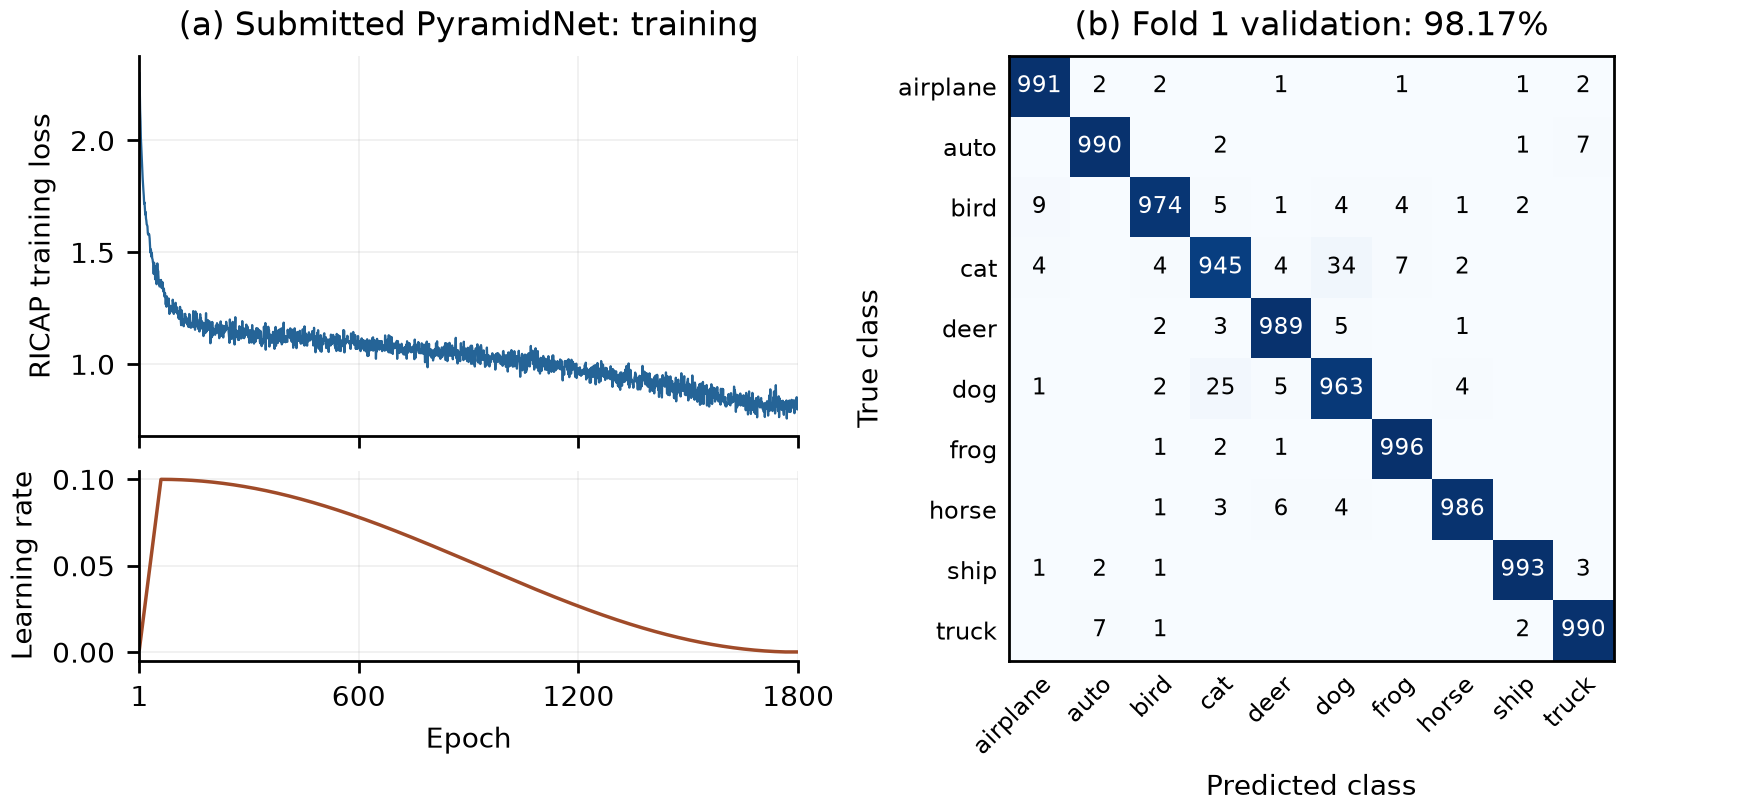

In [3]:
from IPython.display import Image, display
from plot_report import main
main()
display(Image(filename=str(ROOT / "Figures/pyramid_diagnostics.png")))